In [1]:
!pip install -q datasets transformers scikit-learn matplotlib pandas

In [2]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import AutoImageProcessor, ViTForImageClassification

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

Device: cuda


In [3]:
# Stream the dataset rather than materializing all 60,000 images.
train_stream = load_dataset(
    "uoft-cs/cifar10",
    split="train",
    streaming=True
)

test_stream = load_dataset(
    "uoft-cs/cifar10",
    split="test",
    streaming=True
)

def get_image_and_label(example):
    image_key = "img" if "img" in example else "image"
    image = example[image_key].convert("RGB")
    label = int(example["label"])
    return image, label

# Shuffle a limited stream and read only the needed examples.
train_stream = train_stream.shuffle(
    seed=SEED,
    buffer_size=10000
)

test_stream = test_stream.shuffle(
    seed=SEED,
    buffer_size=1000
)

train_pool = [
    get_image_and_label(item)
    for item in train_stream.take(9000)
]

test_data = [
    get_image_and_label(item)
    for item in test_stream.take(1000)
]

random.shuffle(train_pool)

train_data = train_pool[:8000]
val_data = train_pool[8000:9000]

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

Training images: 8000
Validation images: 1000
Testing images: 1000


In [4]:
from torchvision import transforms

class CIFARListDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        image, label = self.data[index]
        image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, int(label)


cnn_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

# Load processor settings used by the pretrained ViT.
model_name = "google/vit-base-patch16-224"
processor = AutoImageProcessor.from_pretrained(model_name)

vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

cnn_train_ds = CIFARListDataset(train_data, cnn_transform)
cnn_val_ds = CIFARListDataset(val_data, cnn_transform)
cnn_test_ds = CIFARListDataset(test_data, cnn_transform)

vit_train_ds = CIFARListDataset(train_data, vit_transform)
vit_val_ds = CIFARListDataset(val_data, vit_transform)
vit_test_ds = CIFARListDataset(test_data, vit_transform)

BATCH_SIZE = 32

cnn_train_loader = DataLoader(
    cnn_train_ds, batch_size=BATCH_SIZE, shuffle=True
)
cnn_val_loader = DataLoader(
    cnn_val_ds, batch_size=BATCH_SIZE, shuffle=False
)
cnn_test_loader = DataLoader(
    cnn_test_ds, batch_size=BATCH_SIZE, shuffle=False
)

vit_train_loader = DataLoader(
    vit_train_ds, batch_size=BATCH_SIZE, shuffle=True
)
vit_val_loader = DataLoader(
    vit_val_ds, batch_size=BATCH_SIZE, shuffle=False
)
vit_test_loader = DataLoader(
    vit_test_ds, batch_size=BATCH_SIZE, shuffle=False
)

print("Datasets prepared successfully.")

Datasets prepared successfully.


In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


cnn = CNN().to(device)

criterion = nn.CrossEntropyLoss()
cnn_optimizer = optim.Adam(cnn.parameters(), lr=0.001)

print(cnn)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=128, out_features=10, bias=True)
)


In [6]:
def evaluate_model(model, loader, is_vit=False):
    model.eval()
    y_true, y_pred = [], []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.time()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_vit:
                outputs = model(pixel_values=images).logits
            else:
                outputs = model(images)

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    if device.type == "cuda":
        torch.cuda.synchronize()

    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "F1-score (%)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "Inference time (s)": time.time() - start
    }

print("Evaluation function defined successfully.")

Evaluation function defined successfully.


In [7]:
def train_model(model, train_loader, val_loader,
                optimizer, epochs=5, is_vit=False):

    history = {
        "train_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            if is_vit:
                outputs = model(pixel_values=images).logits
            else:
                outputs = model(images)

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        val_metrics = evaluate_model(
            model, val_loader, is_vit=is_vit
        )

        history["train_loss"].append(avg_loss)
        history["val_accuracy"].append(
            val_metrics["Accuracy (%)"]
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {avg_loss:.4f} | "
            f"Validation Accuracy: "
            f"{val_metrics['Accuracy (%)']:.2f}%"
        )

    return history

In [8]:
#load ViT
vit = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=10,
    ignore_mismatched_sizes=True
)

vit.config.id2label = {
    i: name for i, name in enumerate(classes)
}
vit.config.label2id = {
    name: i for i, name in enumerate(classes)
}

for param in vit.vit.parameters():
    param.requires_grad = False

vit = vit.to(device)

vit_optimizer = optim.AdamW(
    vit.classifier.parameters(),
    lr=0.001
)

print("Pre-trained ViT loaded successfully.")

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Pre-trained ViT loaded successfully.


In [9]:
def train_vit_model(model, train_loader, val_loader,
                    optimizer, epochs=5):

    history = {"train_loss": [], "val_accuracy": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            # IMPORTANT: Extract logits from ViT output
            outputs = model(pixel_values=images)
            logits = outputs.logits

            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        metrics = evaluate_model(
            model, val_loader, is_vit=True
        )

        history["train_loss"].append(avg_loss)
        history["val_accuracy"].append(metrics["Accuracy (%)"])

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {avg_loss:.4f} | "
            f"Validation Accuracy: "
            f"{metrics['Accuracy (%)']:.2f}%"
        )

    return history

In [10]:
start = time.time()

vit_history = train_vit_model(
    vit,
    vit_train_loader,
    vit_val_loader,
    vit_optimizer,
    epochs=5
)

vit_train_time = time.time() - start

print(f"ViT training time: {vit_train_time:.2f} seconds")

Epoch 1/5 | Loss: 0.2398 | Validation Accuracy: 95.00%
Epoch 2/5 | Loss: 0.0986 | Validation Accuracy: 95.70%
Epoch 3/5 | Loss: 0.0726 | Validation Accuracy: 96.20%
Epoch 4/5 | Loss: 0.0535 | Validation Accuracy: 95.70%
Epoch 5/5 | Loss: 0.0425 | Validation Accuracy: 95.70%
ViT training time: 596.22 seconds


In [11]:
EPOCHS = 5

start = time.time()
cnn_history = train_model(
    cnn,
    cnn_train_loader,
    cnn_val_loader,
    cnn_optimizer,
    epochs=EPOCHS
)
cnn_train_time = time.time() - start

print(f"\nCNN training time: {cnn_train_time:.2f} seconds")

Epoch 1/5 | Loss: 2.0721 | Validation Accuracy: 27.80%
Epoch 2/5 | Loss: 1.8320 | Validation Accuracy: 32.50%
Epoch 3/5 | Loss: 1.7090 | Validation Accuracy: 35.40%
Epoch 4/5 | Loss: 1.6365 | Validation Accuracy: 42.40%
Epoch 5/5 | Loss: 1.5914 | Validation Accuracy: 41.10%

CNN training time: 9.48 seconds


In [12]:
cnn_results = evaluate_model(cnn, cnn_test_loader, is_vit=False)
vit_results = evaluate_model(vit, vit_test_loader, is_vit=True)

cnn_results["Training time (s)"] = cnn_train_time
vit_results["Training time (s)"] = vit_train_time

results = pd.DataFrame(
    [cnn_results, vit_results],
    index=["CNN", "Pre-trained ViT"]
)

print(results.round(2))

                 Accuracy (%)  Precision (%)  Recall (%)  F1-score (%)  \
CNN                      43.2          45.79       42.11         39.22   
Pre-trained ViT          97.1          97.00       97.02         97.00   

                 Inference time (s)  Training time (s)  
CNN                            0.14               9.48  
Pre-trained ViT               12.91             596.22  


In [ ]:
metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]

results[metrics].plot(kind="bar", figsize=(10, 5))

plt.title("CNN vs Pre-trained Vision Transformer")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

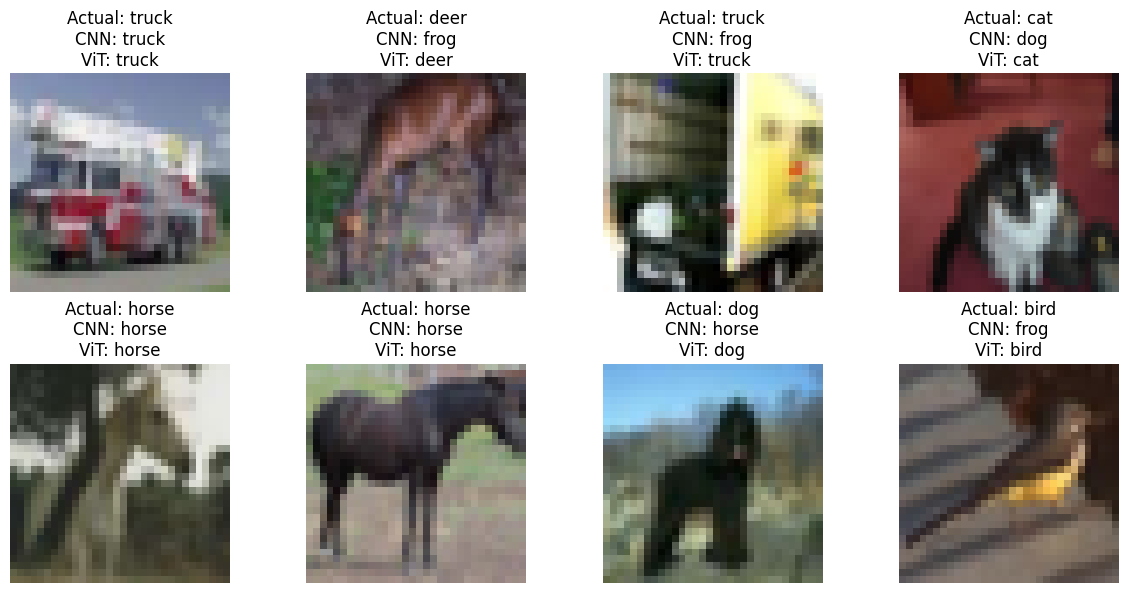

In [14]:
images, labels = next(iter(cnn_test_loader))
vit_images, _ = next(iter(vit_test_loader))

cnn.eval()
vit.eval()

with torch.no_grad():
    cnn_preds = cnn(images.to(device)).argmax(dim=1)

    vit_preds = vit(
        pixel_values=vit_images.to(device)
    ).logits.argmax(dim=1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()

    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(
        f"Actual: {classes[labels[i]]}\n"
        f"CNN: {classes[cnn_preds[i].item()]}\n"
        f"ViT: {classes[vit_preds[i].item()]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()